# 3.6 - Dominant colors and brand-palette distance
Extract representative colors in CIELAB D65, report pixel proportions, and calculate the proportion-weighted nearest-palette Delta E 76 distance. Lower distance indicates closer color similarity, not a brand pass/fail judgment.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

from brandlens.analysis.color_palette import (
    DominantColorSettings,
    extract_dominant_colors,
    measure_color_palette,
    measure_palette_distance,
)

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "config" / "brand_standards.json").is_file()), Path.cwd())
CONFIG_PATH = ROOT / "config" / "brand_standards.json"

## 1. Load configuration
Reads cluster count, seed, palette, and method identifiers. If the file is missing, labeled demonstration defaults are used. Sampling defaults to 50,000 pixels for fitting; proportions use all pixels. Set `max_sample_pixels=None` to fit all pixels. The palette remains provisional; no acceptance threshold is applied.

In [2]:
if CONFIG_PATH.is_file():
    config = json.loads(CONFIG_PATH.read_text(encoding="utf-8"))
    criterion = next(c for c in config["criteria"] if c["criterion_id"] == "color_palette_fit")
    params = criterion["params"]
    for key, expected in {
        "color_space": "CIELAB_D65",
        "distance_metric": "euclidean_delta_e_76",
        "palette_distance_aggregation": "proportion_weighted_mean_nearest",
    }.items():
        if params[key] != expected:
            raise ValueError(f"Unsupported {key}: {params[key]}")
    palette = config["brand_palette"]
    settings = DominantColorSettings(n_clusters=params["n_clusters"], random_seed=params["random_seed"])
    print("Config:", CONFIG_PATH, "Rubric:", config.get("rubric_id"))
else:
    palette = ["#004977", "#D03027", "#FFFFFF"]
    settings = DominantColorSettings()
    print("DEMO DEFAULTS: no brand_standards.json found.")
print("Settings:", settings.to_dict())
print("Palette:", palette)

Config: f:\V_Tech Semesters\MS Thesis\Jupyter_MS\git\visual-brand-audit\config\brand_standards.json Rubric: default-v1-draft
Settings: {'n_clusters': 5, 'random_seed': 42, 'max_sample_pixels': 50000}
Palette: ['#004977', '#D03027', '#FFFFFF']


## 2. Synthetic images with known colors
The exact-palette sample uses the configured colors. All images here are already RGB/sRGB. The gradient has more unique colors than clusters, so it exercises K-means rather than the distinct-color shortcut.

In [3]:
def stripes(hex_colors, width_per_color=80, height=120):
    image = Image.new("RGB", (len(hex_colors) * width_per_color, height))
    for i, color in enumerate(hex_colors):
        image.paste(color, (i * width_per_color, 0, (i + 1) * width_per_color, height))
    return image

weighted = Image.new("RGB", (300, 120), "#004977")
weighted.paste("#D03027", (210, 0, 300, 120))
x = np.linspace(0, 255, 256).astype(np.uint8)
gradient = np.zeros((120, 256, 3), dtype=np.uint8)
gradient[:, :, 0] = x
gradient[:, :, 1] = 255 - x
gradient[:, :, 2] = 90
samples = [
    {"name": "Exact configured palette", "image": stripes(palette)},
    {"name": "70% blue / 30% red", "image": weighted},
    {"name": "Solid white (one color)", "image": Image.new("RGB", (300, 120), "white")},
    {"name": "Green / magenta", "image": stripes(["#00FF00", "#FF00FF"])},
    {"name": "Color gradient", "image": Image.fromarray(gradient)},
]

## 3. Show every image and extracted palette
Bar widths show proportions. Lab centers are retained for distance calculations; RGB/hex values are rounded display approximations. A solid image returns one color even if five are requested.

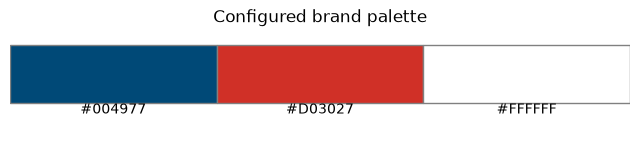

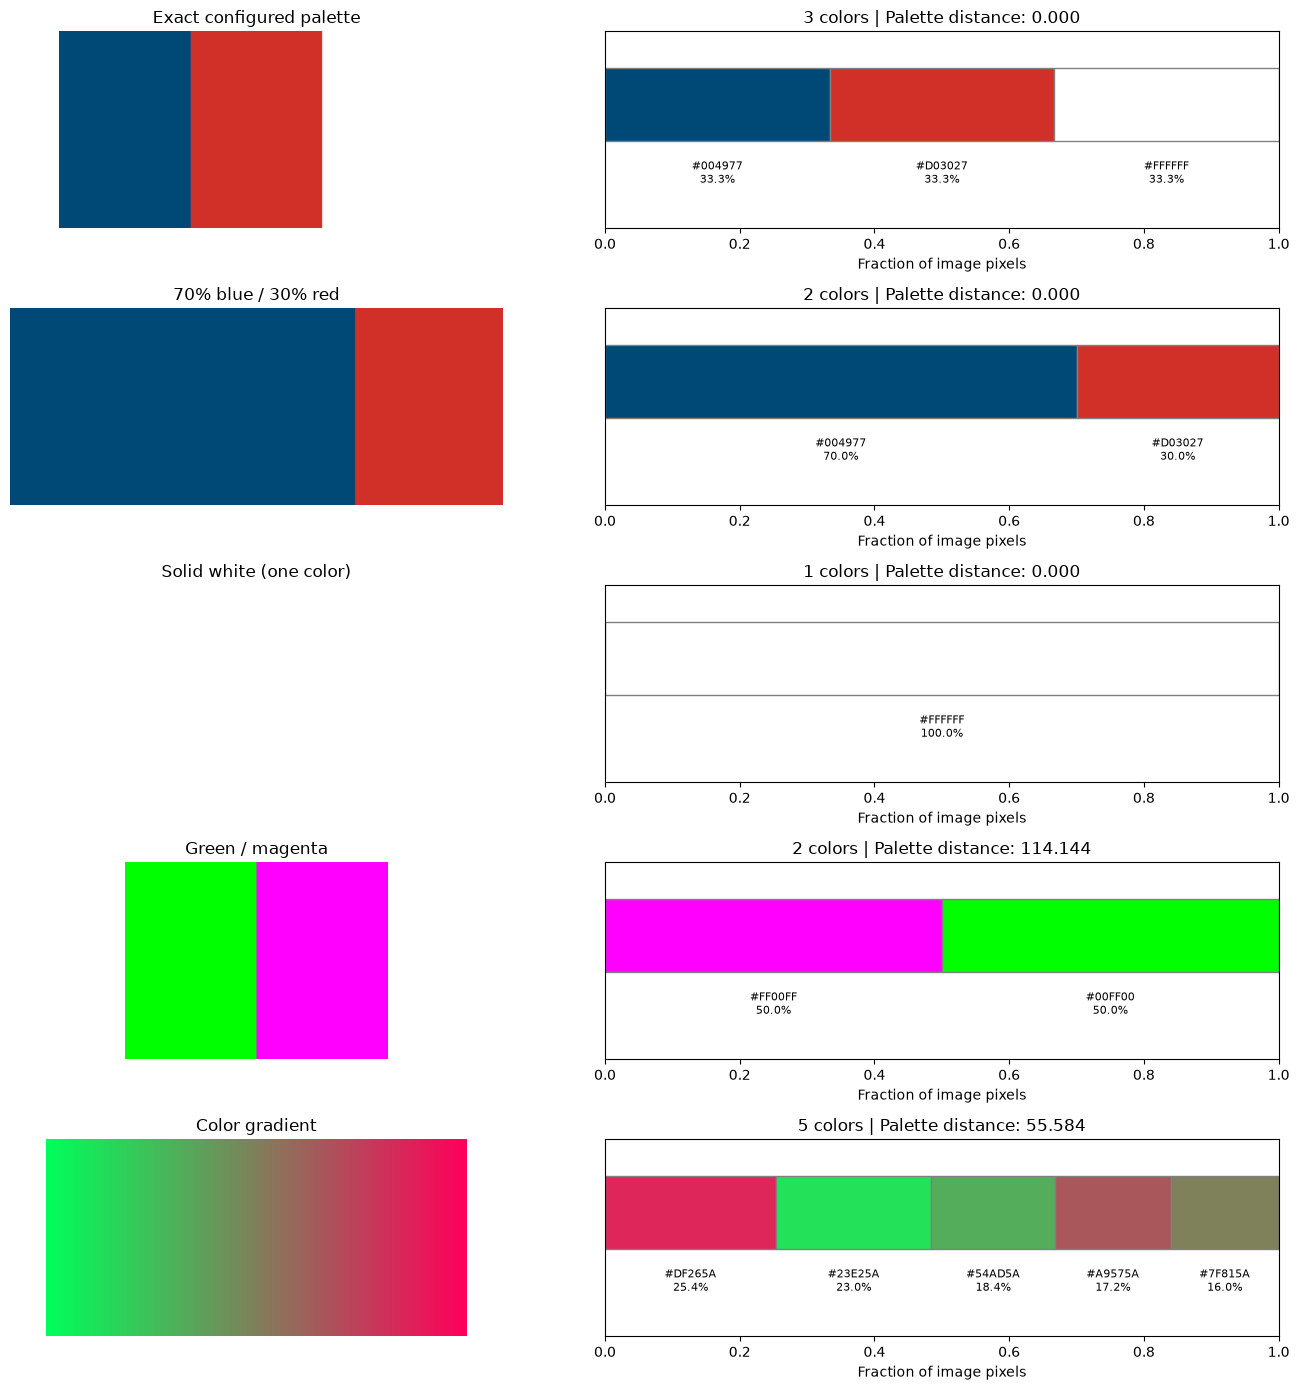

In [4]:
def show_results(items, brand_palette, extraction_settings):
    _fig, axes = plt.subplots(len(items), 2, figsize=(14, 2.8 * len(items)), squeeze=False)
    outputs = {}
    for row, sample in enumerate(items):
        result = measure_color_palette(sample["image"], brand_palette, extraction_settings)
        outputs[sample["name"]] = result
        axes[row, 0].imshow(sample["image"])
        axes[row, 0].set_title(sample["name"])
        axes[row, 0].axis("off")
        ax = axes[row, 1]
        left = 0.0
        for color in result["dominant_colors"]:
            ax.barh(0, color["proportion"], left=left, color=color["hex"], edgecolor="gray", height=0.5)
            ax.text(left + color["proportion"] / 2, -0.38,
                    f"{color['hex']}\n{color['proportion']:.1%}", ha="center", va="top", fontsize=8)
            left += color["proportion"]
        ax.set(xlim=(0, 1), ylim=(-0.85, 0.5), yticks=[], xlabel="Fraction of image pixels")
        ax.set_title(f"{len(result['dominant_colors'])} colors | Palette distance: {result['palette_distance']:.3f}")
    plt.tight_layout()
    plt.show()
    return outputs

fig, ax = plt.subplots(figsize=(8, 1.5))
for i, color in enumerate(palette):
    ax.barh(0, 1, left=i, color=color, edgecolor="gray")
    ax.text(i + 0.5, -0.55, color, ha="center")
ax.set(xlim=(0, len(palette)), ylim=(-1, 0.6), title="Configured brand palette")
ax.axis("off")
plt.show()
results = show_results(samples, palette, settings)

## 4. Inspect the distance calculation
For each cluster, find its nearest brand color and multiply that distance by the cluster's proportion. Their sum is `palette_distance`. Calling the public distance function with a unit-weight cluster exposes each individual distance without accessing private conversion helpers.

In [5]:
selected_name = "70% blue / 30% red"
result = results[selected_name]
contributions = []
print("Color       Proportion    Nearest brand    Delta E 76    Contribution")
for color in result["dominant_colors"]:
    unit_color = {**color, "proportion": 1.0}
    distances = [measure_palette_distance([unit_color], [brand]) for brand in palette]
    nearest_index = int(np.argmin(distances))
    distance = distances[nearest_index]
    contribution = color["proportion"] * distance
    contributions.append(contribution)
    print(f"{color['hex']}     {color['proportion']:8.3f}      {palette[nearest_index]}        {distance:8.3f}       {contribution:8.3f}")
assert np.isclose(sum(contributions), result["palette_distance"])
print("Weighted total:", result["palette_distance"])
print(json.dumps(result, indent=2))

Color       Proportion    Nearest brand    Delta E 76    Contribution
#004977        0.700      #004977           0.000          0.000
#D03027        0.300      #D03027           0.000          0.000
Weighted total: 0.0
{
  "dominant_colors": [
    {
      "rgb": [
        0,
        73,
        119
      ],
      "hex": "#004977",
      "lab": [
        29.534912109375,
        -0.953125,
        -31.609375
      ],
      "proportion": 0.7
    },
    {
      "rgb": [
        208,
        48,
        39
      ],
      "hex": "#D03027",
      "lab": [
        46.4599609375,
        60.828125,
        44.203125
      ],
      "proportion": 0.3
    }
  ],
  "palette_distance": 0.0
}


## 5. Change the brand palette without extracting colors again
Cluster centers and proportions depend on the image and extraction settings. The palette only affects the distance calculation. Several clusters can match the same palette color; unused brand colors are not penalized.

In [6]:
colors = results["70% blue / 30% red"]["dominant_colors"]
comparison_palettes = {
    "Configured": palette,
    "Exact blue/red": ["#004977", "#D03027"],
    "Black/white": ["#000000", "#FFFFFF"],
    "Green/magenta": ["#00FF00", "#FF00FF"],
}
for name, candidate in comparison_palettes.items():
    print(f"{name:18s}: {measure_palette_distance(colors, candidate):.4f}")

Configured        : 0.0000
Exact blue/red    : 0.0000
Black/white       : 56.8062
Green/magenta     : 109.2267


## 6. Known-answer verification
These checks use explicit settings and palettes independently of the configuration file. Repeatability is checked with numerical tolerance; exact bitwise equality across software versions is not assumed.

In [7]:
known_colors = [
    {"lab": [10.0, 0.0, 0.0], "proportion": 0.7},
    {"lab": [40.0, 0.0, 0.0], "proportion": 0.3},
]
assert np.isclose(measure_palette_distance(known_colors, ["#000000"]), 19.0)
explicit = DominantColorSettings(n_clusters=5, max_sample_pixels=None)
known = measure_color_palette(weighted, ["#004977", "#D03027"], explicit)
assert np.allclose([c["proportion"] for c in known["dominant_colors"]], [0.7, 0.3])
assert np.isclose(known["palette_distance"], 0.0, atol=1e-8)
for sample in samples:
    before = sample["image"].tobytes()
    first = extract_dominant_colors(sample["image"], settings)
    second = extract_dominant_colors(sample["image"], settings)
    assert len(first) == len(second)
    assert np.isclose(sum(c["proportion"] for c in first), 1.0)
    for a, b in zip(first, second):
        assert np.allclose(a["lab"], b["lab"], atol=1e-8, rtol=0)
        assert np.isclose(a["proportion"], b["proportion"])
    assert sample["image"].tobytes() == before
print("Known-distance, proportions, repeatability, and preservation checks passed.")

Known-distance, proportions, repeatability, and preservation checks passed.


## 7. Optional real photographs
Add paths below. Existing loading and standardization modules resolve orientation, profiles, and transparency. These measurements do not themselves standardize images. The geometry filter is not applied in this demonstration.

In [8]:
IMAGE_PATHS = [
    # ROOT / "examples" / "data" / "photo.jpg",
]
if IMAGE_PATHS:
    from brandlens.preprocessing.image_io import load_image
    from brandlens.preprocessing.standardization import (
        StandardizationSettings,
        standardize_image,
    )

    real_samples = []
    try:
        for path in IMAGE_PATHS:
            with load_image(path) as original:
                processed = standardize_image(original, StandardizationSettings(max_size=None))
            real_samples.append({"name": Path(path).name, "image": processed})
        real_results = show_results(real_samples, palette, settings)
    finally:
        for sample in real_samples:
            sample["image"].close()
else:
    print("Add paths above to analyze your photographs.")

Add paths above to analyze your photographs.


Notes
- Distance is nonnegative, in Delta E 76 units, and is not restricted to 0–1 or a percentage.
- The score is based on representative cluster centers, not the mean distance of every individual pixel to the brand palette.
- Sampling can miss rare colors; large backgrounds can dominate proportions.
- Color similarity does not establish overall brand alignment or color harmony.
- No pass/fail is generated while the palette-distance threshold is unset.